# Pengumpulan Data: Security Awareness Perusahaan di Indonesia

**Mata kuliah:** Data Mining · **Topik:** Teori pengumpulan data → praktik mengumpulkan data dari sumber open data.

| Tahap | Isi |
|---|---|
| 1. Menentukan kasus | Masalah apa yang ingin diselesaikan dengan Data Mining |
| 2. Menentukan sumber & jenis data | Fitur, label (target), dan dari mana datanya |
| 3. Collect & loading data | Mengambil dataset open data dari GitHub, lalu memuatnya dengan **NumPy, pandas, scikit-learn, matplotlib** |
| 4. Mengenal isi data | Sorting kolom **kategorikal vs numerikal** + jumlahnya, lalu **duplikat, null, zero** (jumlah & persentase) |

> ⚠️ **Data sintetis.** Dataset dibuat dengan `generate_dataset.py` (seed 42) untuk latihan. Kategori dan ambang nilai
> mengikuti regulasi resmi (UU PDP, Indeks KAMI BSSN, PP 7/2021); angkanya **bukan** data perusahaan nyata.

## 1. Menentukan Kasus

**Latar belakang.** Sebagian besar kebocoran data melibatkan faktor manusia — Verizon DBIR 2025 mencatat elemen manusia
pada sekitar 60% kasus. Di Indonesia, UU No. 27/2022 (PDP) dan Indeks KAMI BSSN menuntut perusahaan membuktikan
kesiapan keamanannya. Masalahnya, tingkat *security awareness* sulit diukur langsung dan biasanya baru ketahuan
setelah insiden terjadi.

**Rumusan masalah.**
1. Bisakah kita **memprediksi tingkat security awareness** sebuah perusahaan (Rendah / Sedang / Tinggi) dari profil,
   tata kelola, lingkungan TI, dan perilaku karyawannya?
2. Faktor apa yang paling menentukan, dan **motif serangan** apa yang paling sering menimpa perusahaan dengan awareness rendah?

**Jenis tugas Data Mining.**

| Tugas | Target | Contoh algoritma (minggu depan) |
|---|---|---|
| Klasifikasi | `tingkat_awareness` (Rendah/Sedang/Tinggi) | Decision Tree, Random Forest, Naive Bayes |
| Regresi | `skor_awareness` (0–100) | Linear Regression, Random Forest Regressor |
| Clustering | (tanpa label) profil keamanan | K-Means |

## 2. Menentukan Sumber & Jenis Data

Analogi dengan contoh prediksi harga rumah:

| | Prediksi harga rumah | Kasus ini: security awareness perusahaan |
|---|---|---|
| **Lokasi** | kode pos, koordinat GPS | `provinsi`, `kota`, `kode_pos`, `latitude`, `longitude` |
| **Ukuran / profil** | luas tanah & bangunan, jumlah kamar | `skala_usaha`, `jumlah_karyawan`, `omzet_tahunan_miliar_rp`, `jumlah_cabang` |
| **Umur** | tahun dibangun | `tahun_berdiri` |
| **Kondisi** | — | tata kelola (tim keamanan, SOC, ISO 27001, DPO, anggaran), lingkungan TI (cloud, BYOD, patching, backup), perilaku (pelatihan, click rate phishing, MFA, password bocor) |
| **Riwayat** | — | insiden 12 bulan, **motif serangan**, vektor serangan, kerugian |
| **Label (target)** | harga jual | `tingkat_awareness` (klasifikasi) / `skor_awareness` (regresi) |

**Sumber data yang dipertimbangkan.**

| Sumber | Kelebihan | Kekurangan |
|---|---|---|
| Kaggle | Banyak dataset publik, ada komunitas & notebook | Dataset security awareness tingkat perusahaan Indonesia praktis tidak ada |
| Survei langsung ke perusahaan | Data nyata | Butuh waktu, izin, dan responden banyak |
| Laporan resmi (BSSN, Komdigi, Verizon, IBM) | Kredibel | Hanya angka agregat, bukan per perusahaan |
| **Dataset sintetis di GitHub (dipakai)** | Struktur realistis, dikalibrasi dari laporan resmi, bebas diakses | Bukan data nyata → hasil analisis berupa hipotesis |

Dataset dipublikasikan sebagai **open data di GitHub** dan diakses lewat URL *raw*, persis seperti mengambil dataset
publik lain. Repo: `NullIvy/datamining_04TPLE001`.

In [1]:
from pathlib import Path
import io
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.utils import Bunch
from sklearn.model_selection import train_test_split

print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib  :", plt.matplotlib.__version__)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

BIRU, ABU = "#2a78d6", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": ABU, "xtick.color": ABU, "ytick.color": ABU,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})

numpy       : 2.5.3
pandas      : 3.0.5
scikit-learn: 1.9.1
matplotlib  : 3.11.2


## 3. Collect Data dari Sumber Open Data

Langkah *collect*: unduh file dari GitHub, simpan salinannya ke `data/raw/` beserta waktu pengambilan.
Kalau internet/URL belum siap, notebook memakai file lokal di `data/` supaya tetap bisa jalan.

In [2]:
GITHUB_USER = "NullIvy"
GITHUB_REPO = "datamining_04TPLE001"
URL = (f"https://raw.githubusercontent.com/{GITHUB_USER}/{GITHUB_REPO}"
       "/main/security-awareness/data/security_awareness_indonesia.csv")
LOKAL = Path("data/security_awareness_indonesia.csv")
RAW_DIR = Path("data/raw")
RAW_DIR.mkdir(parents=True, exist_ok=True)

try:
    with urllib.request.urlopen(URL, timeout=15) as resp:
        isi = resp.read()
    sumber = f"GitHub ({URL})"
except Exception as e:
    print(f"Gagal mengambil dari GitHub ({type(e).__name__}) -> pakai file lokal")
    isi = LOKAL.read_bytes()
    sumber = f"Lokal ({LOKAL})"

waktu = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")
FILE_RAW = RAW_DIR / f"security_awareness_{waktu}.csv"
FILE_RAW.write_bytes(isi)

print("Sumber       :", sumber)
print("Disimpan ke  :", FILE_RAW)
print(f"Ukuran file  : {len(isi) / 1024:,.1f} KB")

Sumber       : GitHub (https://raw.githubusercontent.com/NullIvy/datamining_04TPLE001/main/security-awareness/data/security_awareness_indonesia.csv)
Disimpan ke  : data/raw/security_awareness_20261023_211850.csv
Ukuran file  : 2,030.0 KB


## 4. Loading Data dengan NumPy, pandas, scikit-learn, matplotlib

Satu file yang sama dimuat dengan empat library. Tiap library punya peran berbeda:

| Library | Peran | Kelebihan | Keterbatasan |
|---|---|---|---|
| **NumPy** | Array angka untuk komputasi cepat | Cepat & hemat memori | Satu array = satu tipe data; teks jadi sulit |
| **pandas** | Tabel campuran (angka + teks) | Paling praktis untuk eksplorasi | Lebih berat dari NumPy |
| **scikit-learn** | Format siap model (`X`, `y`) | Langsung bisa dipakai algoritma | Butuh data numerik & bersih |
| **matplotlib** | Melihat data secara visual | Pola cepat terlihat | Bukan alat simpan data |

### 4.1 pandas — `read_csv`

In [3]:
# kode_pos berisi angka tapi sebenarnya LABEL -> baca sebagai teks agar angka 0 di depan tidak hilang
df = pd.read_csv(FILE_RAW, dtype={"kode_pos": "string"})
print(f"{df.shape[0]:,} baris × {df.shape[1]} kolom")
df.head()

5,120 baris × 55 kolom


,id_perusahaan,nama_perusahaan,sektor,status_kepemilikan,provinsi,kota,kode_pos,latitude,longitude,skala_usaha,jumlah_karyawan,omzet_tahunan_miliar_rp,tahun_berdiri,jumlah_cabang,kategori_sistem_elektronik,memiliki_tim_keamanan,jumlah_staf_keamanan_it,memiliki_soc,status_iso27001,kebijakan_keamanan_tertulis,kepatuhan_uu_pdp,memiliki_dpo,anggaran_keamanan_persen_it,asuransi_siber,program_bug_bounty,adopsi_cloud,persen_kerja_remote,persen_perangkat_byod,jumlah_vendor_ti,jumlah_akun_admin,rata2_hari_patching,frekuensi_backup,frekuensi_pelatihan_per_tahun,metode_pelatihan,persen_karyawan_terlatih,simulasi_phishing_per_tahun,phishing_click_rate_persen,phishing_report_rate_persen,jumlah_laporan_phishing_karyawan,penerapan_mfa,kebijakan_password,persen_password_bocor,skor_indeks_kami,kategori_indeks_kami,jumlah_insiden_12_bulan,jenis_insiden_utama,motif_serangan_utama,vektor_serangan_awal,penyebab_utama_insiden,waktu_deteksi_jam,lama_downtime_jam,estimasi_kerugian_juta_rp,skor_awareness,tingkat_awareness,tanggal_survei
0,SA-00531,PT Wahana Retail Sejahtera,Ritel & E-commerce,Terbuka (Tbk),Banten,Tangerang Selatan,15827,-6.27464,106.71097,Besar,1170.0,639.90,1977,14,Rendah,Tidak,0,Outsource (MSSP),Belum,Ya,Sebagian,Ya,13.8,Tidak,Tidak,Hybrid,1.9,39.8,14,8,NaN,Mingguan,10,Tatap Muka,73.8,3,11.8,43.9,156,Penuh,Sedang,3.6,484,Cukup Baik,0,Tidak Ada,Tidak Ada,Tidak Ada,Tidak Ada,NaN,0.0,0.0,79.5,Sedang,2026-03-05
1,SA-01730,PT Wira Data Gemilang,Telekomunikasi,BUMN/BUMD,Jawa Barat,Bogor,16588,-6.61504,106.81485,Besar,250.0,130.81,2003,9,Strategis,Ya,7,Tidak Ada,Tersertifikasi,Ya,Patuh,Tidak,3.3,Tidak,Tidak,Cloud-First,0.0,25.2,16,2,38.0,Mingguan,9,E-Learning,69.7,3,19.6,44.5,26,Tidak,Kuat,6.6,461,Pemenuhan Kerangka Kerja Dasar,2,Malware,Finansial,Email Phishing,Kesalahan Manusia,124.8,10.3,389.6,71.8,Sedang,2026-04-24
2,SA-01011,PT Harapan Finansial Lestari,Pemerintahan & BUMN Jasa,BUMN/BUMD,Jawa Barat,Bandung,40940,-6.93205,107.61895,Kecil,32.0,10.10,2015,0,Strategis,Tidak,0,Tidak Ada,Dalam Proses,Tidak,Sebagian,Tidak,7.7,Tidak,Tidak,On-Premise,8.3,20.7,1,1,37.0,Bulanan,5,Gamifikasi,64.6,3,8.7,41.9,7,Tidak,Sedang,10.8,337,Pemenuhan Kerangka Kerja Dasar,2,Phishing,Finansial,Email Phishing,Kesalahan Manusia,233.0,9.8,6.3,59.5,Rendah,2026-07-19
3,SA-01150,PT Mega Trans Nusantara,Logistik & Transportasi,Swasta Nasional,Jawa Tengah,Kudus,59473,-6.83885,110.78399,Menengah,244.0,18.27,1991,1,Strategis,Ya,2,Tidak Ada,Belum,Ya,Patuh,Tidak,6.4,Tidak,Tidak,Hybrid,0.0,34.4,7,3,48.0,Tidak Ada,3,Tatap Muka,60.6,4,29.7,34.1,21,Sebagian,Sedang,8.8,283,Tidak Layak,2,Malware,Hacktivism,Email Phishing,Kredensial Dicuri,371.6,62.6,1358.5,42.2,Rendah,2026-09-24
4,SA-01384,PT Bumi Logistik Gemilang,Kesehatan,Swasta Nasional,DKI Jakarta,Jakarta Barat,11324,-6.14459,106.74997,Besar,405.0,127.43,1971,11,Tinggi,Tidak,0,Internal,Tersertifikasi,Tidak,Patuh,Ya,7.1,Tidak,Tidak,Hybrid,0.0,29.7,20,2,26.0,Bulanan,4,Tatap Muka,71.1,6,14.4,54.5,66,Sebagian,Lemah,5.1,514,Cukup Baik,3,Phishing,Finansial,Pihak Ketiga/Vendor,Pihak Ketiga,91.8,2.5,896.3,71.1,Sedang,2026-04-06


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5120 entries, 0 to 5119
Data columns (total 55 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   id_perusahaan                     5120 non-null   str    
 1   nama_perusahaan                   5120 non-null   str    
 2   sektor                            5120 non-null   str    
 3   status_kepemilikan                5120 non-null   str    
 4   provinsi                          5120 non-null   str    
 5   kota                              5017 non-null   str    
 6   kode_pos                          4966 non-null   string 
 7   latitude                          4969 non-null   float64
 8   longitude                         4969 non-null   float64
 9   skala_usaha                       5120 non-null   str    
 10  jumlah_karyawan                   4967 non-null   float64
 11  omzet_tahunan_miliar_rp           4863 non-null   float64
 12  tahun_berdiri    

### 4.2 NumPy — `genfromtxt` (hanya kolom numerik)

In [5]:
header = FILE_RAW.read_text(encoding="utf-8").splitlines()[0].split(",")
kolom_numerik = df.select_dtypes(include="number").columns.tolist()
idx = [header.index(k) for k in kolom_numerik]

arr = np.genfromtxt(FILE_RAW, delimiter=",", skip_header=1, usecols=idx, dtype=float)
print("Tipe   :", type(arr).__name__, arr.dtype)
print("Shape  :", arr.shape, "(baris, kolom numerik)")
print("NaN    :", int(np.isnan(arr).sum()), "sel kosong")
print("Zero   :", int((arr == 0).sum()), "sel bernilai 0")

Tipe   : ndarray float64
Shape  : (5120, 26) (baris, kolom numerik)
NaN    : 3976 sel kosong
Zero   : 11758 sel bernilai 0


In [6]:
# Statistik per kolom dengan NumPy (nan* mengabaikan sel kosong)
pd.DataFrame({
    "mean": np.nanmean(arr, axis=0),
    "median": np.nanmedian(arr, axis=0),
    "min": np.nanmin(arr, axis=0),
    "max": np.nanmax(arr, axis=0),
}, index=kolom_numerik).round(2)

,mean,median,min,max
latitude,-5.28,-6.23,-8.75,3.69
longitude,108.85,106.89,98.61,140.78
jumlah_karyawan,455.22,190.00,5.00,17740.00
omzet_tahunan_miliar_rp,166.75,39.50,2.09,14918.13
tahun_berdiri,1998.00,1999.00,1970.00,2023.00
jumlah_cabang,4.84,2.00,0.00,25.00
jumlah_staf_keamanan_it,4.78,2.00,0.00,172.00
anggaran_keamanan_persen_it,8.71,8.70,0.50,17.70
persen_kerja_remote,10.41,2.50,0.00,72.50
persen_perangkat_byod,28.22,28.10,0.00,83.80


### 4.3 scikit-learn — `Bunch` (format yang sama dengan `load_iris()`)

Dataset bawaan scikit-learn seperti `load_iris()` dikembalikan sebagai objek `Bunch` berisi `data`, `target`,
`feature_names`, `target_names`. Dataset kita dikemas dengan format yang sama supaya minggu depan bisa langsung
dipakai algoritma.

In [7]:
from sklearn.datasets import load_iris
iris = load_iris()
print("Contoh bawaan:", type(iris).__name__, "| keys:", list(iris.keys())[:5])
print("iris.data shape:", iris.data.shape, "| target:", list(iris.target_names))

Contoh bawaan: Bunch | keys: ['data', 'target', 'frame', 'target_names', 'DESCR']
iris.data shape: (150, 4) | target: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


In [8]:
LABEL = "tingkat_awareness"
URUTAN_LABEL = ["Rendah", "Sedang", "Tinggi"]
TIDAK_DIPAKAI = ["skor_awareness", "waktu_deteksi_jam"]   # skor = label versi angka (bocor), waktu deteksi = null struktural

fitur_numerik = [k for k in kolom_numerik if k not in TIDAK_DIPAKAI]
data_model = df.drop_duplicates()

security_awareness = Bunch(
    data=data_model[fitur_numerik].to_numpy(),
    target=data_model[LABEL].map({v: i for i, v in enumerate(URUTAN_LABEL)}).to_numpy(),
    feature_names=fitur_numerik,
    target_names=np.array(URUTAN_LABEL),
    frame=data_model,
    DESCR="Security Awareness Perusahaan Indonesia (sintetis). Label: tingkat_awareness.",
)
print("keys          :", list(security_awareness.keys()))
print("data shape    :", security_awareness.data.shape)
print("target shape  :", security_awareness.target.shape)
print("target_names  :", list(security_awareness.target_names))

keys          : ['data', 'target', 'feature_names', 'target_names', 'frame', 'DESCR']
data shape    : (5000, 24)
target shape  : (5000,)
target_names  : [np.str_('Rendah'), np.str_('Sedang'), np.str_('Tinggi')]


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    security_awareness.data, security_awareness.target,
    test_size=0.2, random_state=42, stratify=security_awareness.target)

pd.DataFrame({
    "baris": [len(X_train), len(X_test)],
    **{f"{n} (%)": [round((y_train == i).mean() * 100, 1), round((y_test == i).mean() * 100, 1)]
       for i, n in enumerate(URUTAN_LABEL)},
}, index=["train (80%)", "test (20%)"])

,baris,Rendah (%),Sedang (%),Tinggi (%)
train (80%),4000,40.4,41.4,18.3
test (20%),1000,40.3,41.4,18.3


`stratify` menjaga proporsi Rendah/Sedang/Tinggi tetap sama di data latih dan data uji.
Catatan: `X` masih mengandung NaN, jadi minggu depan perlu *imputasi* (atau pakai data bersih dari `sa_cli.py rapikan`).

### 4.4 matplotlib — sekilas isi data

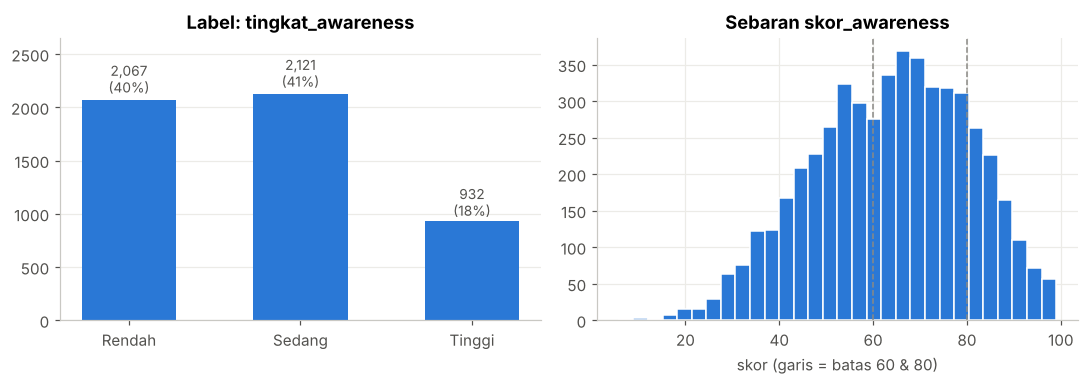

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

label = df[LABEL].value_counts().reindex(URUTAN_LABEL)
axes[0].bar(label.index, label.values, color=BIRU, width=0.55)
for x, v in enumerate(label.values):
    axes[0].text(x, v * 1.02, f"{v:,}\n({v / len(df):.0%})", ha="center", va="bottom", color=ABU, fontsize=9)
axes[0].set_ylim(0, label.max() * 1.25)
axes[0].set_title("Label: tingkat_awareness"); axes[0].grid(axis="x", visible=False)

axes[1].hist(df["skor_awareness"], bins=30, color=BIRU, edgecolor="white", linewidth=1)
for batas in (60, 80):
    axes[1].axvline(batas, color="#8a8984", lw=1, ls="--")
axes[1].set_title("Sebaran skor_awareness"); axes[1].set_xlabel("skor (garis = batas 60 & 80)")
plt.tight_layout(); plt.show()

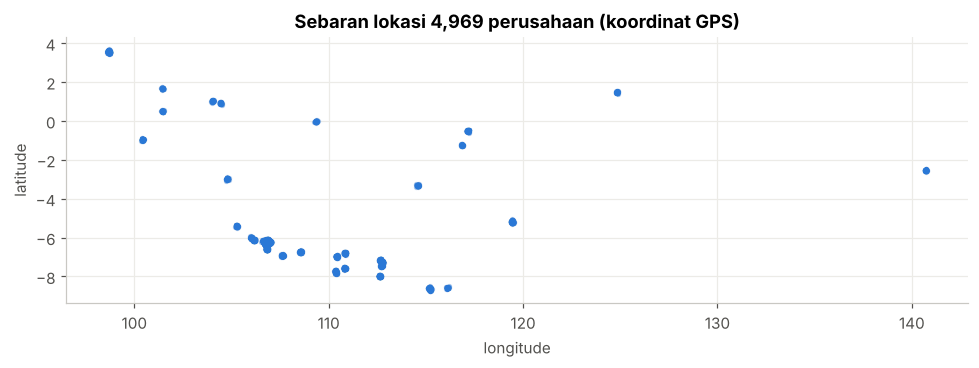

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
data_peta = df.dropna(subset=["latitude", "longitude"])
ax.scatter(data_peta["longitude"], data_peta["latitude"], s=6, alpha=0.35, color=BIRU)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title(f"Sebaran lokasi {len(data_peta):,} perusahaan (koordinat GPS)")
ax.set_aspect("equal"); plt.tight_layout(); plt.show()

## 5. Sorting Jenis Data: Kategorikal vs Numerikal

- **Numerikal** = angka yang bisa dihitung. **Diskret**: hasil hitungan (bilangan bulat, mis. jumlah insiden).
  **Kontinu**: hasil ukur, bisa desimal (mis. persentase, kerugian).
- **Kategorikal** = label/kelompok. **Nominal**: tanpa urutan (sektor). **Ordinal**: berurutan (Rendah < Sedang < Tinggi).
  **Biner**: dua nilai (Ya/Tidak).
- **Jebakan:** `kode_pos` berbentuk angka tapi **kategorikal** — tidak masuk akal menghitung rata-rata kode pos.

In [12]:
numerik = df.select_dtypes(include="number").columns.tolist()
kategorikal = df.select_dtypes(exclude="number").columns.tolist()

print(f"Numerikal   : {len(numerik)} kolom")
print(f"Kategorikal : {len(kategorikal)} kolom (termasuk identitas & tanggal)")
print(f"Total       : {df.shape[1]} kolom")

Numerikal   : 26 kolom
Kategorikal : 29 kolom (termasuk identitas & tanggal)
Total       : 55 kolom


In [13]:
ORDINAL = ["skala_usaha", "kategori_sistem_elektronik", "status_iso27001", "kepatuhan_uu_pdp", "frekuensi_backup",
           "penerapan_mfa", "kebijakan_password", "kategori_indeks_kami", "tingkat_awareness"]
BINER = ["memiliki_tim_keamanan", "kebijakan_keamanan_tertulis", "memiliki_dpo", "asuransi_siber", "program_bug_bounty"]
IDENTITAS = ["id_perusahaan", "nama_perusahaan"]

def sub_jenis(k):
    if k in IDENTITAS: return "Kategorikal - identitas"
    if k == "tanggal_survei": return "Tanggal"
    if k == "kode_pos": return "Kategorikal - nominal (angka sebagai label)"
    if k in ORDINAL: return "Kategorikal - ordinal"
    if k in BINER: return "Kategorikal - biner"
    if k in kategorikal: return "Kategorikal - nominal"
    desimal = (df[k].dropna() % 1 != 0).any()
    return "Numerikal - kontinu" if desimal or "persen" in k else "Numerikal - diskret"

jenis = pd.DataFrame({
    "kolom": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "jenis": [sub_jenis(k) for k in df.columns],
    "nilai_unik": [df[k].nunique() for k in df.columns],
    "contoh": [df[k].dropna().iloc[0] for k in df.columns],
})
jenis = jenis.sort_values(["jenis", "kolom"]).reset_index(drop=True)
jenis

,kolom,dtype,jenis,nilai_unik,contoh
0,asuransi_siber,str,Kategorikal - biner,2,Tidak
1,kebijakan_keamanan_tertulis,str,Kategorikal - biner,2,Ya
2,memiliki_dpo,str,Kategorikal - biner,2,Ya
3,memiliki_tim_keamanan,str,Kategorikal - biner,2,Tidak
4,program_bug_bounty,str,Kategorikal - biner,2,Tidak
5,id_perusahaan,str,Kategorikal - identitas,5000,SA-00531
6,nama_perusahaan,str,Kategorikal - identitas,5000,PT Wahana Retail Sejahtera
7,adopsi_cloud,str,Kategorikal - nominal,3,Hybrid
8,jenis_insiden_utama,str,Kategorikal - nominal,8,Tidak Ada
9,kota,str,Kategorikal - nominal,43,Tangerang Selatan


In [14]:
ringkas_jenis = (jenis.assign(kelompok=jenis["jenis"].str.split(" - ").str[0])
                 .groupby(["kelompok", "jenis"]).size().to_frame("jumlah_kolom"))
ringkas_jenis["persen"] = (ringkas_jenis["jumlah_kolom"] / len(jenis) * 100).round(1)
ringkas_jenis

jumlah_kolom  persen
kelompok    jenis                                                            
Kategorikal Kategorikal - biner                                     5     9.1
            Kategorikal - identitas                                 2     3.6
            Kategorikal - nominal                                  11    20.0
            Kategorikal - nominal (angka sebagai label)             1     1.8
            Kategorikal - ordinal                                   9    16.4
Numerikal   Numerikal - diskret                                    12    21.8
            Numerikal - kontinu                                    14    25.5
Tanggal     Tanggal                                                 1     1.8

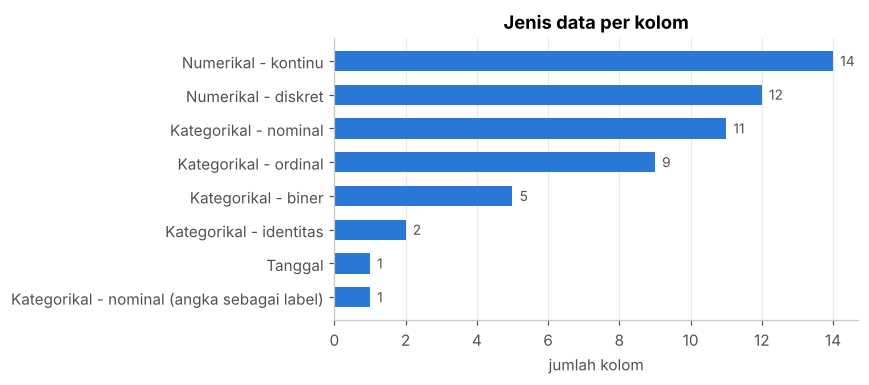

In [15]:
r = jenis["jenis"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(r.index, r.values, color=BIRU, height=0.6)
for y, v in enumerate(r.values):
    ax.text(v + 0.2, y, str(v), va="center", color=ABU, fontsize=9)
ax.set_xlabel("jumlah kolom"); ax.set_title("Jenis data per kolom")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

### 5.1 Data persentase & jumlah — kolom kategorikal

In [16]:
def jumlah_persen(kolom):
    vc = df[kolom].value_counts(dropna=False)
    return pd.DataFrame({"jumlah": vc, "persen": (vc / len(df) * 100).round(2)})

for k in ["sektor", "motif_serangan_utama", "tingkat_awareness"]:
    display(jumlah_persen(k).rename_axis(k))

,jumlah,persen
sektor,,
Manufaktur,572,11.17
Teknologi Informasi,508,9.92
Perbankan,507,9.90
Ritel & E-commerce,490,9.57
Pendidikan,474,9.26
Kesehatan,456,8.91
Fintech,428,8.36
Asuransi & Multifinance,384,7.50
Logistik & Transportasi,357,6.97


,jumlah,persen
motif_serangan_utama,,
Finansial,1716,33.52
Tidak Ada,1217,23.77
Pencurian Data/Spionase,901,17.60
Hacktivism,481,9.39
Iseng/Uji Kemampuan,468,9.14
Insider/Balas Dendam,337,6.58


,jumlah,persen
tingkat_awareness,,
Sedang,2121,41.43
Rendah,2067,40.37
Tinggi,932,18.20


In [17]:
# Ringkas semua kolom kategorikal: jumlah kategori, kategori terbanyak, dan persentasenya
fitur_kat = [k for k in kategorikal if k not in IDENTITAS + ["tanggal_survei", "kode_pos"]]
pd.DataFrame({
    "jumlah_kategori": [df[k].nunique() for k in fitur_kat],
    "terbanyak": [df[k].mode().iat[0] for k in fitur_kat],
    "jumlah_terbanyak": [int((df[k] == df[k].mode().iat[0]).sum()) for k in fitur_kat],
    "persen_terbanyak": [round((df[k] == df[k].mode().iat[0]).mean() * 100, 1) for k in fitur_kat],
}, index=fitur_kat)

,jumlah_kategori,terbanyak,jumlah_terbanyak,persen_terbanyak
sektor,13,Manufaktur,572,11.2
status_kepemilikan,4,Swasta Nasional,3542,69.2
provinsi,20,DKI Jakarta,1391,27.2
kota,43,Jakarta Pusat,286,5.6
skala_usaha,3,Menengah,2584,50.5
kategori_sistem_elektronik,3,Tinggi,2251,44.0
memiliki_tim_keamanan,2,Ya,3073,60.0
memiliki_soc,3,Tidak Ada,2273,44.4
status_iso27001,3,Belum,2860,55.9
kebijakan_keamanan_tertulis,2,Ya,3341,65.3


### 5.2 Data persentase & jumlah — kolom numerikal

In [18]:
df[numerik].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
latitude,4969.0,-5.28,3.07,-8.75,-6.91,-6.23,-6.02,3.69
longitude,4969.0,108.85,5.77,98.61,106.76,106.89,110.87,140.78
jumlah_karyawan,4967.0,455.22,854.36,5.00,87.00,190.00,406.00,17740.00
omzet_tahunan_miliar_rp,4863.0,166.75,542.99,2.09,21.63,39.50,115.55,14918.13
tahun_berdiri,5120.0,1998.00,15.95,1970.00,1984.00,1999.00,2012.00,2023.00
jumlah_cabang,5120.0,4.84,5.56,0.00,1.00,2.00,10.00,25.00
jumlah_staf_keamanan_it,5120.0,4.78,9.73,0.00,0.00,2.00,5.00,172.00
anggaran_keamanan_persen_it,4809.0,8.71,2.83,0.50,6.80,8.70,10.70,17.70
persen_kerja_remote,4918.0,10.41,13.80,0.00,0.00,2.50,18.20,72.50
persen_perangkat_byod,4864.0,28.22,15.32,0.00,17.30,28.10,38.80,83.80


## 6. Sorting Duplikat, Null, dan Zero

| Istilah | Arti | Contoh di dataset ini |
|---|---|---|
| **Duplikat** | Baris yang muncul lebih dari satu kali (seluruh isinya sama) | Data perusahaan terinput dua kali |
| **Null** | Sel kosong pada suatu baris | Responden tidak mengisi omzet |
| **Zero** | Sel yang nilainya **0** — ada isinya, bukan kosong | Perusahaan tanpa insiden → `jumlah_insiden_12_bulan = 0` |

Null ≠ zero: null berarti *tidak diketahui*, zero berarti *diketahui dan nilainya nol*.

### 6.1 Duplikat

In [19]:
n_dup = int(df.duplicated().sum())
n_dup_semua = int(df.duplicated(keep=False).sum())
print(f"Baris duplikat (salinan kedua dst.)      : {n_dup:,} ({n_dup / len(df):.2%})")
print(f"Baris yang terlibat duplikasi (+aslinya) : {n_dup_semua:,}")
print(f"ID perusahaan berulang                   : {df['id_perusahaan'].duplicated().sum():,}")
print(f"Baris unik setelah duplikat dibuang      : {len(df) - n_dup:,}")

Baris duplikat (salinan kedua dst.)      : 120 (2.34%)
Baris yang terlibat duplikasi (+aslinya) : 240
ID perusahaan berulang                   : 120
Baris unik setelah duplikat dibuang      : 5,000


In [20]:
# Sorting: tampilkan baris duplikat berdampingan dengan aslinya
dup = df[df.duplicated(keep=False)].sort_values("id_perusahaan")
dup[["id_perusahaan", "nama_perusahaan", "sektor", "kota", "skor_awareness", "tanggal_survei"]].head(8)

,id_perusahaan,nama_perusahaan,sektor,kota,skor_awareness,tanggal_survei
58,SA-00024,PT Nusa Solusi Abadi,Manufaktur,Jakarta Pusat,58.7,2026-07-31
2932,SA-00024,PT Nusa Solusi Abadi,Manufaktur,Jakarta Pusat,58.7,2026-07-31
161,SA-00030,PT Yasa Retail Jaya,Manufaktur,Jakarta Pusat,66.1,2026-04-02
1876,SA-00030,PT Yasa Retail Jaya,Manufaktur,Jakarta Pusat,66.1,2026-04-02
98,SA-00066,PT Kencana Industri Global,Teknologi Informasi,Batam,84.1,2026-05-10
1600,SA-00066,PT Kencana Industri Global,Teknologi Informasi,Batam,84.1,2026-05-10
42,SA-00080,PT Bahtera Digital Persada,Media & Kreatif,Bandung,20.0,2026-02-03
4186,SA-00080,PT Bahtera Digital Persada,Media & Kreatif,Bandung,20.0,2026-02-03


In [21]:
# Duplikat per sektor (jumlah & persen dari total duplikat)
d = df[df.duplicated()]["sektor"].value_counts()
pd.DataFrame({"jumlah_duplikat": d, "persen": (d / d.sum() * 100).round(1)})

,jumlah_duplikat,persen
sektor,,
Fintech,13,10.8
Manufaktur,13,10.8
Teknologi Informasi,12,10.0
Pendidikan,12,10.0
Logistik & Transportasi,11,9.2
Kesehatan,11,9.2
Perbankan,11,9.2
Telekomunikasi,8,6.7
Asuransi & Multifinance,8,6.7


### 6.2 Null

In [22]:
n_null = int(df.isna().sum().sum())
print(f"Total sel null            : {n_null:,} dari {df.size:,} sel ({n_null / df.size:.2%})")
print(f"Kolom yang punya null     : {int((df.isna().sum() > 0).sum())} dari {df.shape[1]}")
print(f"Baris dengan ≥1 null      : {int(df.isna().any(axis=1).sum()):,} dari {len(df):,}")
print(f"Baris lengkap tanpa null  : {int(df.notna().all(axis=1).sum()):,}")

Total sel null            : 4,851 dari 281,600 sel (1.72%)
Kolom yang punya null     : 19 dari 55
Baris dengan ≥1 null      : 3,182 dari 5,120
Baris lengkap tanpa null  : 1,938


In [23]:
null = df.isna().sum()
tabel_null = (null[null > 0].sort_values(ascending=False).to_frame("jumlah_null")
              .assign(persen=lambda t: (t["jumlah_null"] / len(df) * 100).round(2),
                      jenis=lambda t: [sub_jenis(k) for k in t.index]))
tabel_null

,jumlah_null,persen,jenis
waktu_deteksi_jam,1217,23.77,Numerikal - kontinu
rata2_hari_patching,355,6.93,Numerikal - diskret
anggaran_keamanan_persen_it,311,6.07,Numerikal - kontinu
persen_password_bocor,309,6.04,Numerikal - kontinu
omzet_tahunan_miliar_rp,257,5.02,Numerikal - kontinu
persen_perangkat_byod,256,5.00,Numerikal - kontinu
phishing_click_rate_persen,256,5.00,Numerikal - kontinu
persen_karyawan_terlatih,203,3.96,Numerikal - kontinu
kepatuhan_uu_pdp,203,3.96,Kategorikal - ordinal
persen_kerja_remote,202,3.95,Numerikal - kontinu


In [24]:
tanpa_insiden = df["jumlah_insiden_12_bulan"].eq(0)
print("waktu_deteksi_jam null & tanpa insiden :", int((df["waktu_deteksi_jam"].isna() & tanpa_insiden).sum()))
print("waktu_deteksi_jam null & ADA insiden   :", int((df["waktu_deteksi_jam"].isna() & ~tanpa_insiden).sum()))
print("latitude null tapi longitude terisi    :", int((df["latitude"].isna() & df["longitude"].notna()).sum()))

waktu_deteksi_jam null & tanpa insiden : 1217
waktu_deteksi_jam null & ADA insiden   : 0
latitude null tapi longitude terisi    : 0


- `waktu_deteksi_jam` → **null struktural**: kosong karena perusahaan memang tidak mengalami insiden. Tidak boleh diisi.
- `latitude`/`longitude` → hilang **berpasangan** (GPS tidak terekam).
- Kolom lain → **null acak** (2–7%), seperti responden melewatkan pertanyaan.

### 6.3 Zero

In [25]:
zero = (df[numerik] == 0).sum()
tabel_zero = (zero[zero > 0].sort_values(ascending=False).to_frame("jumlah_zero")
              .assign(persen=lambda t: (t["jumlah_zero"] / len(df) * 100).round(2)))
print(f"Total sel zero: {int(zero.sum()):,} di {len(tabel_zero)} kolom numerik")
tabel_zero

Total sel zero: 11,758 di 14 kolom numerik


,jumlah_zero,persen
persen_kerja_remote,2317,45.25
lama_downtime_jam,2113,41.27
jumlah_staf_keamanan_it,2047,39.98
jumlah_cabang,1225,23.93
jumlah_insiden_12_bulan,1217,23.77
estimasi_kerugian_juta_rp,1177,22.99
persen_password_bocor,375,7.32
simulasi_phishing_per_tahun,339,6.62
persen_perangkat_byod,208,4.06
frekuensi_pelatihan_per_tahun,194,3.79


Cara membaca zero:

- **Zero wajar (informasi):** `jumlah_insiden_12_bulan`, `estimasi_kerugian_juta_rp`, `lama_downtime_jam` = 0 artinya
  tidak ada insiden/kerugian. `persen_kerja_remote` = 0 artinya semua kerja di kantor. `jumlah_cabang` = 0 artinya tidak punya cabang.
- **Zero yang perlu dicek konsistensinya:** `jumlah_staf_keamanan_it` = 0 harus sejalan dengan `memiliki_tim_keamanan = "Tidak"`.

In [26]:
pd.crosstab(df["jumlah_staf_keamanan_it"].eq(0).map({True: "staf = 0", False: "staf > 0"}),
            df["memiliki_tim_keamanan"], margins=True, margins_name="Total")

memiliki_tim_keamanan,Tidak,Ya,Total
jumlah_staf_keamanan_it,,,
staf = 0,2047,0,2047
staf > 0,0,3073,3073
Total,2047,3073,5120


### 6.4 Ringkasan kualitas data per kolom

In [27]:
kualitas = pd.DataFrame({
    "jenis": [sub_jenis(k) for k in df.columns],
    "jumlah_null": df.isna().sum().values,
    "jumlah_zero": [int((df[k] == 0).sum()) if k in numerik else 0 for k in df.columns],
}, index=df.columns)
kualitas["persen_null"] = (kualitas["jumlah_null"] / len(df) * 100).round(2)
kualitas["persen_zero"] = (kualitas["jumlah_zero"] / len(df) * 100).round(2)
kualitas = kualitas[(kualitas["jumlah_null"] > 0) | (kualitas["jumlah_zero"] > 0)]
kualitas.sort_values(["jumlah_null", "jumlah_zero"], ascending=False)

,jenis,jumlah_null,jumlah_zero,persen_null,persen_zero
waktu_deteksi_jam,Numerikal - kontinu,1217,0,23.77,0.00
rata2_hari_patching,Numerikal - diskret,355,0,6.93,0.00
anggaran_keamanan_persen_it,Numerikal - kontinu,311,0,6.07,0.00
persen_password_bocor,Numerikal - kontinu,309,375,6.04,7.32
omzet_tahunan_miliar_rp,Numerikal - kontinu,257,0,5.02,0.00
persen_perangkat_byod,Numerikal - kontinu,256,208,5.00,4.06
phishing_click_rate_persen,Numerikal - kontinu,256,0,5.00,0.00
persen_karyawan_terlatih,Numerikal - kontinu,203,187,3.96,3.65
kepatuhan_uu_pdp,Kategorikal - ordinal,203,0,3.96,0.00
persen_kerja_remote,Numerikal - kontinu,202,2317,3.95,45.25


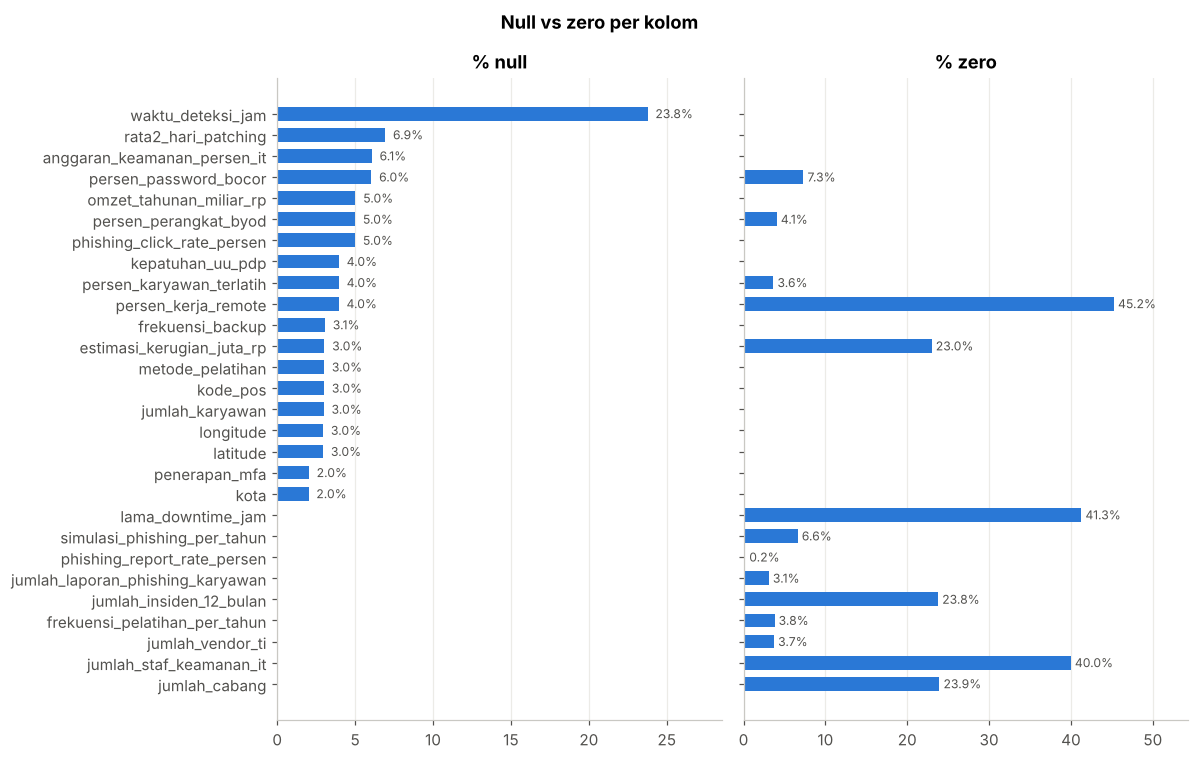

In [28]:
k = kualitas.sort_values("persen_null")
fig, axes = plt.subplots(1, 2, figsize=(11, 7), sharey=True)
for ax, kolom, judul in [(axes[0], "persen_null", "% null"), (axes[1], "persen_zero", "% zero")]:
    ax.barh(k.index, k[kolom], color=BIRU, height=0.65)
    for y, v in enumerate(k[kolom]):
        if v > 0:
            ax.text(v + 0.5, y, f"{v:.1f}%", va="center", color=ABU, fontsize=8)
    ax.set_title(judul); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, max(k[kolom].max() * 1.2, 5))
plt.suptitle("Null vs zero per kolom", fontweight="bold")
plt.tight_layout(); plt.show()

In [29]:
ringkasan = pd.DataFrame({
    "item": ["Baris", "Kolom", "Kolom numerikal", "Kolom kategorikal (termasuk ID & tanggal)",
             "Baris duplikat", "Sel null", "Kolom ber-null", "Sel zero", "Kolom ber-zero"],
    "jumlah": [len(df), df.shape[1], len(numerik), len(kategorikal),
               n_dup, n_null, int((df.isna().sum() > 0).sum()), int(zero.sum()), len(tabel_zero)],
})
ringkasan["persen"] = ["", "", f"{len(numerik) / df.shape[1]:.1%}", f"{len(kategorikal) / df.shape[1]:.1%}",
                       f"{n_dup / len(df):.2%} baris", f"{n_null / df.size:.2%} sel", "",
                       f"{zero.sum() / df[numerik].size:.2%} sel numerik", ""]
ringkasan

,item,jumlah,persen
0,Baris,5120,
1,Kolom,55,
2,Kolom numerikal,26,47.3%
3,Kolom kategorikal (termasuk ID & tanggal),29,52.7%
4,Baris duplikat,120,2.34% baris
5,Sel null,4851,1.72% sel
6,Kolom ber-null,19,
7,Sel zero,11758,8.83% sel numerik
8,Kolom ber-zero,14,


## 7. Sekilas: Motif Serangan vs Tingkat Awareness

Pratinjau pertanyaan kedua di rumusan masalah. Hanya perusahaan yang mengalami insiden yang dihitung.

In [30]:
kena = df.drop_duplicates().query("jumlah_insiden_12_bulan > 0")
tabel_motif = pd.crosstab(kena["motif_serangan_utama"], kena["tingkat_awareness"],
                          normalize="columns").mul(100).round(1)[URUTAN_LABEL]
tabel_motif["jumlah_perusahaan"] = kena["motif_serangan_utama"].value_counts()
tabel_motif.sort_values("jumlah_perusahaan", ascending=False)

tingkat_awareness,Rendah,Sedang,Tinggi,jumlah_perusahaan
motif_serangan_utama,,,,
Finansial,42.2,44.0,47.9,1670
Pencurian Data/Spionase,22.3,23.7,23.9,881
Hacktivism,12.2,13.7,9.6,473
Iseng/Uji Kemampuan,14.3,11.0,7.5,454
Insider/Balas Dendam,9.1,7.6,11.1,334


In [31]:
top = (pd.crosstab(kena["sektor"], kena["motif_serangan_utama"], normalize="index").mul(100)
       .idxmax(axis=1).to_frame("motif_terbanyak"))
top["persen"] = pd.crosstab(kena["sektor"], kena["motif_serangan_utama"], normalize="index").mul(100).max(axis=1).round(1)
top.sort_values("persen", ascending=False)

,motif_terbanyak,persen
sektor,,
Perbankan,Finansial,64.4
Fintech,Finansial,63.3
Asuransi & Multifinance,Finansial,55.5
Logistik & Transportasi,Finansial,53.3
Teknologi Informasi,Finansial,52.3
Ritel & E-commerce,Finansial,45.9
Manufaktur,Finansial,43.4
Kesehatan,Finansial,41.1
Telekomunikasi,Pencurian Data/Spionase,40.1


## 8. Kesimpulan

| Pertanyaan | Jawaban |
|---|---|
| Kasus | Prediksi `tingkat_awareness` perusahaan (klasifikasi) + faktor & motif serangan yang berpengaruh |
| Sumber data | Dataset sintetis open data di GitHub, dikalibrasi dari UU PDP, Indeks KAMI BSSN, PP 7/2021, Verizon DBIR |
| Loading | pandas (tabel campuran), NumPy (array numerik), scikit-learn (`Bunch` + `train_test_split`), matplotlib (visual) |
| Jenis data | Lihat tabel di bagian 5 — numerikal (diskret & kontinu) vs kategorikal (nominal, ordinal, biner) |
| Duplikat, null, zero | Lihat ringkasan di bagian 6.4 |

**Langkah berikutnya:** `python klasifikasi_awareness.py` — melatih Decision Tree untuk memprediksi `tingkat_awareness`.